# Task 9 — Model Comparison & Selection
### QFI Internship · Market Risk Project · Phase 9
**Prepared by:** Arham Shah

---

**Objective.** Choose the VaR/ES model to run in production. Passing backtests is a *gate*, not a ranking, because Task 8 showed the tests have little power. Among the models that pass, we rank forecasts with **proper scoring rules** and test whether the differences are **statistically significant** before recommending one.

**What this notebook delivers**
- A scorecard on identical dates: coverage, ES test, Basel capital, stability, and **quantile (tick) loss** and **FZ0 joint VaR–ES loss**
- **Diebold–Mariano tests** (HAC-robust) showing which differences in accuracy are real
- **Robustness:** winners across all 9 window × confidence cells, and rolling performance through time
- A transparent, two-stage **decision rule** (gate, then score, then a parsimony tie-break), with no arbitrary weights
- Export of `Model_Comparison.csv`, `DM_Tests.csv` and `Model_Recommendation.json` for Task 10

> **Pipeline:** Task 3 Portfolio → Task 4 HS → Task 5 EWMA → Task 6 GARCH → Task 7 GJR-GARCH → Task 8 Backtesting → **Task 9 Model selection** → Task 10 →

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. How to compare risk models properly
**Why not just count exceptions?** A model can hit 1% exactly with a VaR that is far too high on calm days and far too low on stressed days.
**Proper scoring rules** reward a forecast for being right *day by day*, and they're minimised in expectation only by the true quantile (or ES).

**Quantile (tick) loss** for a VaR forecast q_t = −VaR_t at tail level α = 1 − c:
$$QL_t = (\alpha - \mathbf 1_{\{r_t<q_t\}})(r_t - q_t)$$

**FZ0 loss** (Fissler–Ziegel; Patton, Ziegel & Chen 2019) scores **VaR and ES together**. ES alone can't be scored, but the pair can.
With q = −VaR and e = −ES (both negative):
$$L^{FZ0}_t = -\frac{1}{\alpha e_t}\mathbf 1_{\{r_t\le q_t\}}(q_t-r_t) + \frac{q_t}{e_t} + \ln(-e_t) - 1$$
Lower is better for both. Units don't matter, only differences between models.

**Diebold–Mariano test.** For two models A and B, d_t = L_A,t − L_B,t. DM = mean(d) / HAC-se(d) is approximately N(0,1).
If |DM| < 1.96, the data can't tell the models apart.

**Decision rule (set before looking at results):**
1. **Gate:** the model passes the Task 8 battery at the headline (99% / 250d).
2. **Score:** among models that pass, rank by mean FZ0 loss.
3. **Tie-break:** if the leader isn't *significantly* better (DM p > 0.05) than another passing model, treat them as equally accurate and prefer, in order:
   (a) the model that passes the Task 8 battery in **more of the 9 cells** (robustness), (b) the **lower average capital**, (c) the **fewer parameters**.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the portfolio, the toolkit, every model's forecasts and the Task 8 results

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


In [5]:
# ---- Shared volatility engine: EWMA (Task 5), GARCH (Task 6), GJR (Task 7) ----
from scipy.optimize import minimize
from scipy.special import gammaln
REFIT_EVERY, MIN_EST, EWMA_SEED = 21, 500, 30

def ewma_sigma(r, lam=EWMA_LAMBDA, seed=EWMA_SEED):
    e2 = np.asarray(r, float) ** 2; h0 = e2[:seed].mean()
    h = np.r_[h0, lfilter([1 - lam], [1, -lam], e2[:-1], zi=[lam * h0])[0]]
    return pd.Series(np.sqrt(h), index=r.index)

def backcast(e, n=75):
    w = 0.94 ** np.arange(min(n, len(e))); w /= w.sum()
    return float(w @ e[:len(w)] ** 2)

def vol_var(e, omega, alpha, beta, gamma=0.0):
    """h_t = omega + (alpha + gamma*1[e_{t-1}<0]) e_{t-1}^2 + beta h_{t-1}.  gamma = 0 -> GARCH(1,1)."""
    h0 = backcast(e)
    u = omega + (alpha + gamma * (e[:-1] < 0)) * e[:-1] ** 2
    return np.r_[h0, lfilter([1.0], [1.0, -beta], u, zi=[beta * h0])[0]]

def nll(p, x, dist, asym):
    mu, omega, alpha, beta = p[:4]
    gamma = p[4] if asym else 0.0
    e = x - mu
    h = np.maximum(vol_var(e, omega, alpha, beta, gamma), 1e-10)
    if dist == 'normal':
        ll = -0.5 * (np.log(2 * np.pi) + np.log(h) + e * e / h)
    else:
        nu = p[-1]
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
              - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(e * e / (h * (nu - 2))))
    return -ll.sum()

def fit_vol(r, dist='normal', asym=False, x0=None):
    """Gaussian or Student-t (Q)MLE of GARCH(1,1) or GJR-GARCH(1,1,1). Returns in percent units internally."""
    x = np.asarray(r, float) * 100
    v = x.var()
    tb = [(2.1, 100)] if dist == 't' else []
    if asym:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.02, 0.88, 0.10] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (0.0, 0.5), (0.0, 0.9999), (0.0, 0.5)] + tb
        con = lambda p: 0.9999 - p[2] - p[3] - 0.5 * p[4]
    else:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.08, 0.88] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (1e-6, 0.5), (0.0, 0.9999)] + tb
        con = lambda p: 0.9999 - p[2] - p[3]
    res = minimize(nll, x0, args=(x, dist, asym), method='SLSQP', bounds=bnds,
                   constraints={'type': 'ineq', 'fun': con}, options={'maxiter': 500, 'ftol': 1e-10})
    p = res.x
    gamma = p[4] if asym else 0.0
    pers = p[2] + p[3] + 0.5 * gamma
    k, ll = len(p), -res.fun
    return {'dist': dist, 'asym': asym, 'mu': p[0] / 100, 'omega': p[1] / 1e4, 'alpha': p[2], 'beta': p[3],
            'gamma': gamma, 'nu': p[-1] if dist == 't' else np.nan, 'persistence': pers,
            'long_run_vol_ann': np.sqrt(p[1] / 1e4 / (1 - pers) * TRADING_DAYS),
            'half_life': np.log(0.5) / np.log(pers), 'loglik': ll,
            'aic': 2 * k - 2 * ll, 'bic': k * np.log(len(x)) - 2 * ll, 'converged': bool(res.success), '_x': p}

def vol_sigma(r, P):
    """One-day-ahead conditional sigma_t (decimal) for the whole series under parameters P."""
    e = (np.asarray(r, float) - P['mu']) * 100
    return pd.Series(np.sqrt(vol_var(e, P['omega'] * 1e4, P['alpha'], P['beta'], P['gamma'])) / 100, index=r.index)

def vol_next(r, P):
    e = np.asarray(r, float) - P['mu']
    h = vol_sigma(r, P).iloc[-1] ** 2
    return float(np.sqrt(P['omega'] + (P['alpha'] + P['gamma'] * (e[-1] < 0)) * e[-1] ** 2 + P['beta'] * h))

def oos_fhs(r, dist, asym):
    """Filtered HS with the volatility model re-estimated every REFIT_EVERY days on past data only."""
    n = len(r)
    sig_oos = pd.Series(np.nan, index=r.index)
    panel = {(w, c): pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES']) for w in WINDOWS for c in CONFIDENCES}
    hist, x0 = [], None
    for b in range(MIN_EST, n, REFIT_EVERY):
        P = fit_vol(r.iloc[:b], dist, asym, x0); x0 = P['_x']
        end = min(b + REFIT_EVERY, n)
        rr = r.iloc[:end]
        s = vol_sigma(rr, P)
        zz = (rr / s).to_numpy()
        sig_oos.iloc[b:end] = s.iloc[b:end].values
        for (w, c), df in panel.items():
            lo = max(b, w)
            if lo >= end: continue
            sw = sliding_window_view(zz[lo - w:end - 1], w)
            q = np.quantile(sw, 1 - c, axis=1); m = sw <= q[:, None]
            df.iloc[lo:end, 0] = -q * s.iloc[lo:end].values
            df.iloc[lo:end, 1] = -(sw * m).sum(1) / m.sum(1) * s.iloc[lo:end].values
        hist.append({'Estimated through': r.index[b - 1], **{k: P[k] for k in
                     ['mu', 'omega', 'alpha', 'gamma', 'beta', 'nu', 'persistence', 'long_run_vol_ann', 'half_life', 'converged']}})
    return panel, sig_oos, pd.DataFrame(hist).set_index('Estimated through')

def best_dist(asym):
    fits = {d: fit_vol(returns, d, asym) for d in ['normal', 't']}
    return min(fits, key=lambda d: fits[d]['bic']), fits

def build_model(m):
    """Rebuild any model's forecast panel exactly as its own task does (used if a file is missing)."""
    if m == 'HS':
        return {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
    if m == 'EWMA':
        s = ewma_sigma(returns)
        return {(w, c): rolling_fhs(returns, s, w, c) for w in WINDOWS for c in CONFIDENCES}
    asym = (m == 'GJR')
    d, _ = best_dist(asym)
    return oos_fhs(returns, d, asym)[0]

COLORS.setdefault('GJR', '#9B2242')
print('Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).')

Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).


In [6]:
# ---- Load every model's forecasts (Tasks 4-7); rebuild any that are missing ----
FILES   = {'HS': 'HS_VaR.csv', 'EWMA': 'EWMA_VaR.csv', 'GARCH': 'GARCH_VaR.csv', 'GJR': 'GJR_VaR.csv'}
TASK_OF = {'HS': 4, 'EWMA': 5, 'GARCH': 6, 'GJR': 7}
LABEL   = {'HS': 'Historical Simulation', 'EWMA': 'EWMA-FHS', 'GARCH': 'GARCH-FHS', 'GJR': 'GJR-GARCH-FHS'}
COLORS['GJR'] = '#9B2242'

def panel_from_file(m, path):
    df = pd.read_csv(path, index_col=0, parse_dates=True).reindex(returns.index)
    assert np.allclose(df['Return'], returns), f'{path} was built on a different portfolio'
    return {(w, c): pd.DataFrame({'VaR': df[f'{m}_VaR_{w}d_{tag(c)}_Ret'], 'ES': df[f'{m}_ES_{w}d_{tag(c)}_Ret']})
            for w in WINDOWS for c in CONFIDENCES}

MODELS, ORIGIN = {}, {}
for m, f in FILES.items():
    if os.path.exists(f):
        MODELS[m], ORIGIN[m] = panel_from_file(m, f), f'{f} (Task {TASK_OF[m]})'
    else:
        MODELS[m], ORIGIN[m] = build_model(m), f'rebuilt with the Task {TASK_OF[m]} engine (file not found)'
for m in MODELS:
    first = MODELS[m][(HEADLINE_W, HEADLINE_CL)]['VaR'].first_valid_index()
    print(f'{LABEL[m]:<22} <- {ORIGIN[m]:<55} first forecast {first:%d %b %Y}')

def common_dates(w):
    idx = returns.index
    for P in MODELS.values():
        idx = idx.intersection(P[(w, 0.99)]['VaR'].dropna().index)
    return idx
COMMON = {w: common_dates(w) for w in WINDOWS}
print('\nCommon evaluation samples: ' + ', '.join(f'{w}d: {COMMON[w][0]:%b %Y} -> {COMMON[w][-1]:%b %Y} ({len(COMMON[w])} days)' for w in WINDOWS))

Historical Simulation  <- HS_VaR.csv (Task 4)                                     first forecast 23 Jul 2021
EWMA-FHS               <- EWMA_VaR.csv (Task 5)                                   first forecast 23 Jul 2021
GARCH-FHS              <- GARCH_VaR.csv (Task 6)                                  first forecast 21 Jul 2022
GJR-GARCH-FHS          <- GJR_VaR.csv (Task 7)                                    first forecast 21 Jul 2022



Common evaluation samples: 250d: Jul 2022 -> Jul 2026 (1006 days), 500d: Jul 2022 -> Jul 2026 (1006 days), 750d: Jul 2023 -> Jul 2026 (756 days)


In [7]:
# ---- Backtesting functions (shared by Tasks 8 and 9) -------------------------
def christoffersen(hit):
    """Christoffersen (1998) independence LR test -> (LR, p, (n00, n01, n10, n11))."""
    h = np.asarray(hit, int); a, b = h[:-1], h[1:]
    n00, n01 = int(((a == 0) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
    n10, n11 = int(((a == 1) & (b == 0)).sum()), int(((a == 1) & (b == 1)).sum())
    xl = lambda k, p: k * np.log(p) if (k > 0 and p > 0) else 0.0
    N = n00 + n01 + n10 + n11
    pi = (n01 + n11) / N
    p01 = n01 / (n00 + n01) if n00 + n01 else 0.0
    p11 = n11 / (n10 + n11) if n10 + n11 else 0.0
    lr = -2 * ((xl(n00 + n10, 1 - pi) + xl(n01 + n11, pi))
               - (xl(n00, 1 - p01) + xl(n01, p01) + xl(n10, 1 - p11) + xl(n11, p11)))
    lr = max(lr, 0.0)
    return lr, stats.chi2.sf(lr, 1), (n00, n01, n10, n11)

def es_ratio_test(r, var, es, n_boot=5000, seed=7):
    """ES backtest: on exception days, loss/ES - 1 should average 0. One-sided bootstrap p (H1: ES too small)."""
    hit = r < -var
    k = int(hit.sum())
    if k < 3:
        return np.nan, np.nan
    u = (-r[hit] / es[hit] - 1).to_numpy()
    m = u.mean()
    boot = np.random.default_rng(seed).choice(u - m, size=(n_boot, k), replace=True).mean(1)
    return m, float((boot >= m).mean())

def full_backtest(m, w, c, dates=None):
    dates = COMMON[w] if dates is None else dates
    P = MODELS[m][(w, c)]
    v, e, r = P['VaR'].reindex(dates), P['ES'].reindex(dates), returns.reindex(dates)
    hit = (r < -v).astype(int)
    n, x = len(v), int(hit.sum())
    lr_uc, p_uc = kupiec(x, n, c)
    lr_ind, p_ind, (n00, n01, n10, n11) = christoffersen(hit.values)
    p_cc = stats.chi2.sf(lr_uc + lr_ind, 2)
    x250 = int(hit.iloc[-250:].sum())
    es_u, es_p = es_ratio_test(r, v, e)
    ok = (p_uc > 0.05) and (p_cc > 0.05) and (np.isnan(es_p) or es_p > 0.05) and (c != 0.99 or x250 < 10)
    return {'Model': m, 'Window': w, 'Confidence': c, 'Start': dates[0].date(), 'Days': n,
            'Exceptions': x, 'Expected': n * (1 - c), 'Rate': x / n,
            'Kupiec p': p_uc, 'Indep. p': p_ind, 'CC p': p_cc, 'n01': n01, 'n11': n11,
            'ES excess': es_u, 'ES test p': es_p, 'Last 250d exc.': x250,
            'Basel zone': basel_zone(x250) if c == 0.99 else '-', 'Verdict': 'PASS' if ok else 'FAIL',
            'Avg VaR %': v.mean(), 'VaR churn %': v.diff().abs().mean()}

def basel_capital(m, w=HEADLINE_W):
    """Basel 2.5-style market-risk charge: max(VaR10_t, k_t * mean VaR10 over 60d), k from the trailing 250d exceptions."""
    v = MODELS[m][(w, 0.99)]['VaR']
    hit = (returns < -v).astype(float).where(v.notna())
    x250 = hit.rolling(250, min_periods=250).sum().shift(1)           # only exceptions already observed
    k = x250.map(lambda x: np.nan if np.isnan(x) else BASEL_MULT.get(int(x), 4.0))
    var10 = v * start_value * np.sqrt(10)
    return pd.DataFrame({'VaR10': var10, 'k': k, 'x250': x250,
                         'Capital': np.maximum(var10, k * var10.rolling(60).mean())})

def style_full(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'FAIL': '#B03A2E'}
    pcols = ['Kupiec p', 'Indep. p', 'CC p', 'ES test p']
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Indep. p': '{:.3f}', 'CC p': '{:.3f}', 'ES excess': '{:+.1%}', 'ES test p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'VaR churn %': '{:.3%}'}, na_rep='-')
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Basel zone', 'Verdict'])
             .map(lambda v: 'background-color:#F6DDD9' if isinstance(v, float) and v < 0.05 else '', subset=pcols)
             .hide(axis='index'))
print('Backtest functions loaded.')

Backtest functions loaded.


In [8]:
RES = pd.DataFrame([full_backtest(m, w, c) for w in WINDOWS for c in CONFIDENCES for m in MODELS])
if os.path.exists('Backtest_Results.csv'):
    t8 = pd.read_csv('Backtest_Results.csv')
    assert (t8.sort_values(['Window', 'Confidence', 'Model'])['Exceptions'].values ==
            RES.sort_values(['Window', 'Confidence', 'Model'])['Exceptions'].values).all()
    print('Consistency check passed: backtest results identical to Task 8.')
else:
    print('Backtest_Results.csv not found - recomputed with the Task 8 functions.')
CAP = {m: basel_capital(m) for m in MODELS}
COMPLEXITY = {'HS': 0, 'EWMA': 1, 'GARCH': 4, 'GJR': 5}      # number of estimated volatility parameters (simplicity tie-break)

Consistency check passed: backtest results identical to Task 8.


## 3. Scoring functions

In [9]:
def tick_loss(r, v, c):
    a, q = 1 - c, -v
    return (a - (r < q).astype(float)) * (r - q)

def fz0_loss(r, v, e, c):
    a, q, s = 1 - c, -v, -e
    return -(r <= q).astype(float) * (q - r) / (a * s) + q / s + np.log(-s) - 1

def dm_test(d, lag=None):
    d = np.asarray(d, float); T = len(d)
    lag = lag or int(np.floor(T ** (1 / 3)))
    dc = d - d.mean()
    lrv = dc @ dc / T + 2 * sum((1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / T for k in range(1, lag + 1))
    stat = d.mean() / np.sqrt(lrv / T)
    return stat, 2 * stats.norm.sf(abs(stat))

# sanity check: the true quantile must beat a biased one under both losses (simulated Student-t returns)
sim = pd.Series(stats.t.rvs(5, size=200_000, random_state=3) * 0.01)
qt, et = -np.quantile(sim, 0.01), -sim[sim <= np.quantile(sim, 0.01)].mean()
for name, f in [('tick', lambda k: tick_loss(sim, pd.Series(k * qt, index=sim.index), 0.99).mean()),
                ('FZ0', lambda k: fz0_loss(sim, pd.Series(k * qt, index=sim.index), pd.Series(k * et, index=sim.index), 0.99).mean())]:
    vals = {k: f(k) for k in [0.8, 1.0, 1.2]}
    assert vals[1.0] < vals[0.8] and vals[1.0] < vals[1.2]
print('Scoring rules verified: the true VaR/ES scores better than versions scaled 20% too low or too high.')

def losses(m, w, c, dates):
    P = MODELS[m][(w, c)]
    r, v, e = returns.reindex(dates), P['VaR'].reindex(dates), P['ES'].reindex(dates)
    return tick_loss(r, v, c), fz0_loss(r, v, e, c)

Scoring rules verified: the true VaR/ES scores better than versions scaled 20% too low or too high.


## 4. Headline scorecard (99% / 250d, identical dates)

In [10]:
w, c = HEADLINE_W, HEADLINE_CL
d = COMMON[w]
cap_d = d
for m in MODELS: cap_d = cap_d.intersection(CAP[m]['Capital'].dropna().index)
L = {m: losses(m, w, c, d) for m in MODELS}
bt = RES[(RES.Window == w) & (RES.Confidence == c)].set_index('Model')
SC = pd.DataFrame({m: {
    'Exceptions': bt.loc[m, 'Exceptions'], 'Expected': bt.loc[m, 'Expected'], 'Kupiec p': bt.loc[m, 'Kupiec p'],
    'CC p': bt.loc[m, 'CC p'], 'ES test p': bt.loc[m, 'ES test p'], 'Basel zone': bt.loc[m, 'Basel zone'],
    'Gate': bt.loc[m, 'Verdict'], 'Avg VaR %': bt.loc[m, 'Avg VaR %'],
    'Avg capital % NAV': (CAP[m]['Capital'] / start_value).reindex(cap_d).mean(),
    'VaR churn %': bt.loc[m, 'VaR churn %'], 'Tick loss (bps)': L[m][0].mean() * 1e4, 'FZ0 loss': L[m][1].mean(),
    'Vol params': COMPLEXITY[m]} for m in MODELS}).T
SC.index = [LABEL[m] for m in SC.index]
for k in SC.columns:
    if k not in ('Basel zone', 'Gate'): SC[k] = pd.to_numeric(SC[k])
num = ['Avg capital % NAV', 'Tick loss (bps)', 'FZ0 loss']
(SC.style.format({'Expected': '{:.1f}', 'Kupiec p': '{:.3f}', 'CC p': '{:.3f}', 'ES test p': '{:.3f}', 'Avg VaR %': '{:.2%}',
                  'Avg capital % NAV': '{:.1%}', 'VaR churn %': '{:.3%}', 'Tick loss (bps)': '{:.3f}', 'FZ0 loss': '{:.4f}'})
   .highlight_min(subset=num, color='#D5F0E3', props='font-weight:bold;background-color:#D5F0E3')
   .map(lambda v: f'color:{"#2E7D68" if v == "PASS" else "#B03A2E"};font-weight:bold' if v in ('PASS', 'FAIL') else '', subset=['Gate']))

,Exceptions,Expected,Kupiec p,CC p,ES test p,Basel zone,Gate,Avg VaR %,Avg capital % NAV,VaR churn %,Tick loss (bps),FZ0 loss,Vol params
Historical Simulation,11,10.1,0.769,0.258,0.007,GREEN,FAIL,3.57%,31.3%,0.007%,4.798,-3.0287,0
EWMA-FHS,15,10.1,0.145,0.275,0.177,GREEN,PASS,3.56%,32.2%,0.123%,4.538,-3.0933,1
GARCH-FHS,14,10.1,0.239,0.410,0.103,GREEN,PASS,3.47%,31.5%,0.129%,4.566,-3.0833,4
GJR-GARCH-FHS,14,10.1,0.239,0.410,0.165,GREEN,PASS,3.36%,30.7%,0.129%,4.493,-3.0964,5


## 5. Are the differences real? Diebold–Mariano tests
Each cell is the DM statistic for **row minus column** FZ0 loss. Negative (green) means the row model is more accurate. Stars mark significance: * 10%, ** 5%, *** 1%.

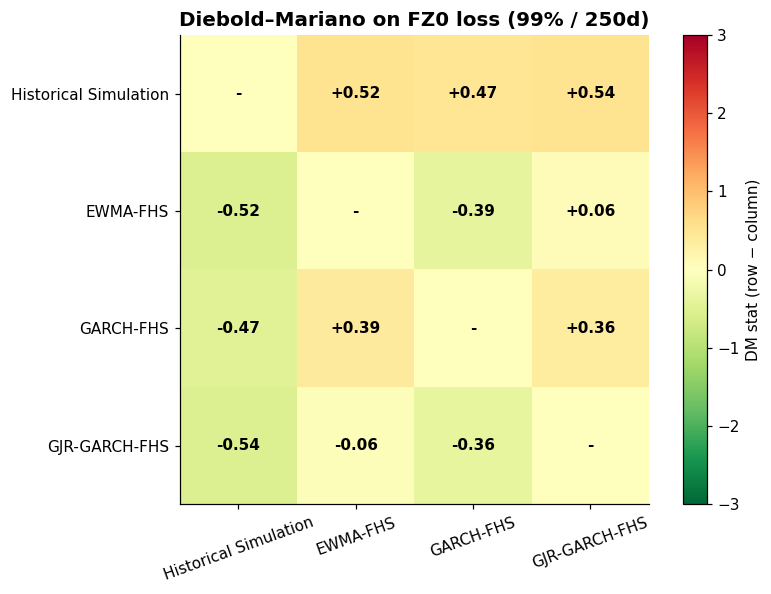

In [11]:
names = list(MODELS)
DM = pd.DataFrame(index=names, columns=names, dtype=float); DMp = DM.copy()
for a in names:
    for b in names:
        if a != b:
            DM.loc[a, b], DMp.loc[a, b] = dm_test(L[a][1].values - L[b][1].values)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
vals = DM.values.astype(float)
im = ax.imshow(np.nan_to_num(vals), cmap='RdYlGn_r', vmin=-3, vmax=3)
star = lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, '-' if i == j else f'{vals[i, j]:+.2f}{star(DMp.values[i, j])}', ha='center', va='center', fontweight='bold')
ax.set_xticks(range(len(names)), [LABEL[n] for n in names], rotation=20); ax.set_yticks(range(len(names)), [LABEL[n] for n in names])
ax.grid(False); plt.colorbar(im, fraction=0.046, label='DM stat (row − column)')
ax.set_title('Diebold–Mariano on FZ0 loss (99% / 250d)')
plt.tight_layout(); plt.show()
dm_long = pd.DataFrame([{'Model A': LABEL[a], 'Model B': LABEL[b], 'DM stat (A-B)': DM.loc[a, b], 'p-value': DMp.loc[a, b]}
                        for a in names for b in names if a < b])

## 6. Robustness: does the winner depend on the window or confidence level?

In [12]:
rows = []
for w_ in WINDOWS:
    for c_ in CONFIDENCES:
        dd = COMMON[w_]
        fz = {m: losses(m, w_, c_, dd)[1].mean() for m in MODELS}
        tk = {m: losses(m, w_, c_, dd)[0].mean() for m in MODELS}
        gate = RES[(RES.Window == w_) & (RES.Confidence == c_)].set_index('Model')['Verdict']
        passers = [m for m in MODELS if gate[m] == 'PASS']
        rows.append({'Window': w_, 'Confidence': c_, 'Passing models': ', '.join(passers) or 'none',
                     'Best FZ0 (all)': min(fz, key=fz.get), 'Best tick (all)': min(tk, key=tk.get),
                     'Best FZ0 among passers': min(passers, key=fz.get) if passers else '-',
                     **{f'FZ0 {m}': fz[m] for m in MODELS}})
ROB = pd.DataFrame(rows)
display(ROB.style.format({'Confidence': '{:.1%}', **{f'FZ0 {m}': '{:.4f}' for m in MODELS}}).hide(axis='index'))
wins = pd.DataFrame({k: ROB[k].value_counts() for k in ['Best FZ0 (all)', 'Best tick (all)', 'Best FZ0 among passers']}).fillna(0).astype(int).drop('-', errors='ignore')
print('Number of the 9 cells won:'); display(wins)

Window,Confidence,Passing models,Best FZ0 (all),Best tick (all),Best FZ0 among passers,FZ0 HS,FZ0 EWMA,FZ0 GARCH,FZ0 GJR
250,95.0%,"EWMA, GARCH, GJR",GJR,GJR,GJR,-3.4874,-3.5148,-3.5385,-3.5817
250,99.0%,"EWMA, GARCH, GJR",GJR,GJR,GJR,-3.0287,-3.0933,-3.0833,-3.0964
250,99.5%,none,GJR,GJR,-,-2.7911,-2.9637,-2.9547,-2.9687
500,95.0%,"HS, EWMA, GARCH, GJR",GJR,GJR,GJR,-3.4365,-3.5196,-3.5426,-3.5799
500,99.0%,"HS, EWMA, GARCH, GJR",GJR,GJR,GJR,-2.9465,-3.0936,-3.0898,-3.0977
500,99.5%,"HS, GJR",GJR,GJR,GJR,-2.8135,-2.9365,-2.9358,-2.9672
750,95.0%,EWMA,GJR,GJR,EWMA,-3.5384,-3.5575,-3.5857,-3.6158
750,99.0%,GJR,HS,GJR,GJR,-3.1487,-3.0921,-3.1200,-3.1397
750,99.5%,"EWMA, GARCH, GJR",EWMA,EWMA,EWMA,-2.9909,-3.0615,-3.0297,-3.0267


Number of the 9 cells won:


,Best FZ0 (all),Best tick (all),Best FZ0 among passers
EWMA,1,1,2
GJR,7,8,6
HS,1,0,0


### Performance through time
Rolling 250-day mean FZ0 loss **relative to HS** (below zero means better than HS). This shows *when* each model earns its keep.

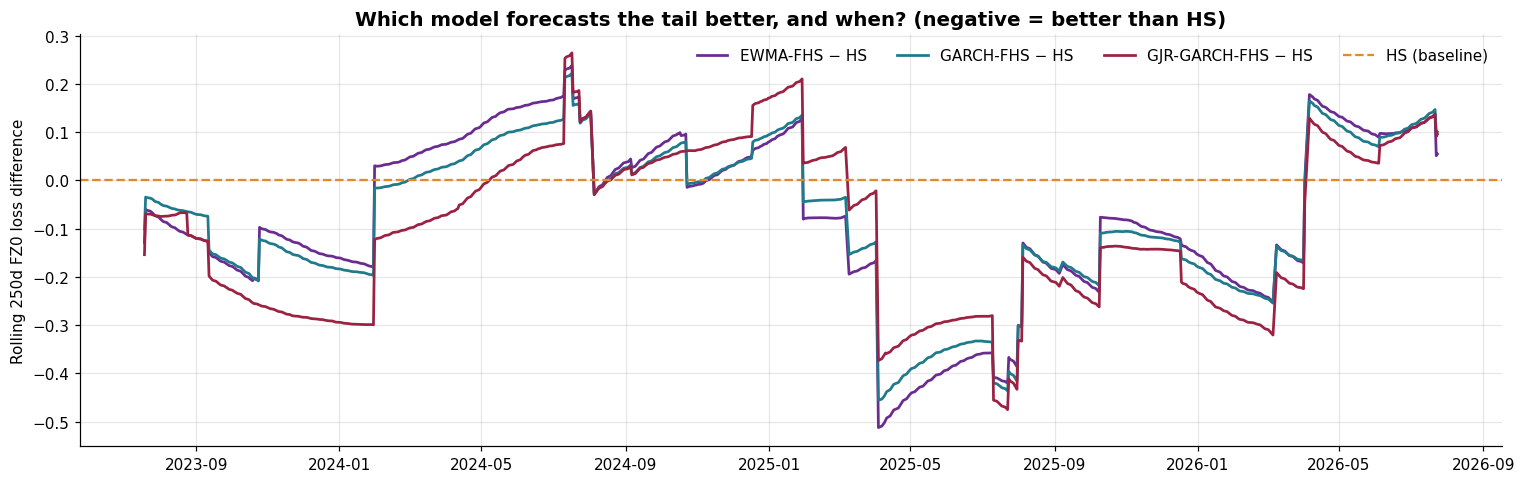

In [13]:
fig, ax = plt.subplots(figsize=(14, 4.5))
base = L['HS'][1]
for m in MODELS:
    if m == 'HS': continue
    ax.plot((L[m][1] - base).rolling(250).mean(), color=COLORS[m], lw=1.8, label=f'{LABEL[m]} − HS')
ax.axhline(0, color=COLORS['HS'], lw=1.5, ls='--', label='HS (baseline)')
ax.set_ylabel('Rolling 250d FZ0 loss difference'); ax.legend(ncol=4)
ax.set_title('Which model forecasts the tail better, and when? (negative = better than HS)')
plt.tight_layout(); plt.show()

## 7. Accuracy vs capital: the trade-off a risk committee sees

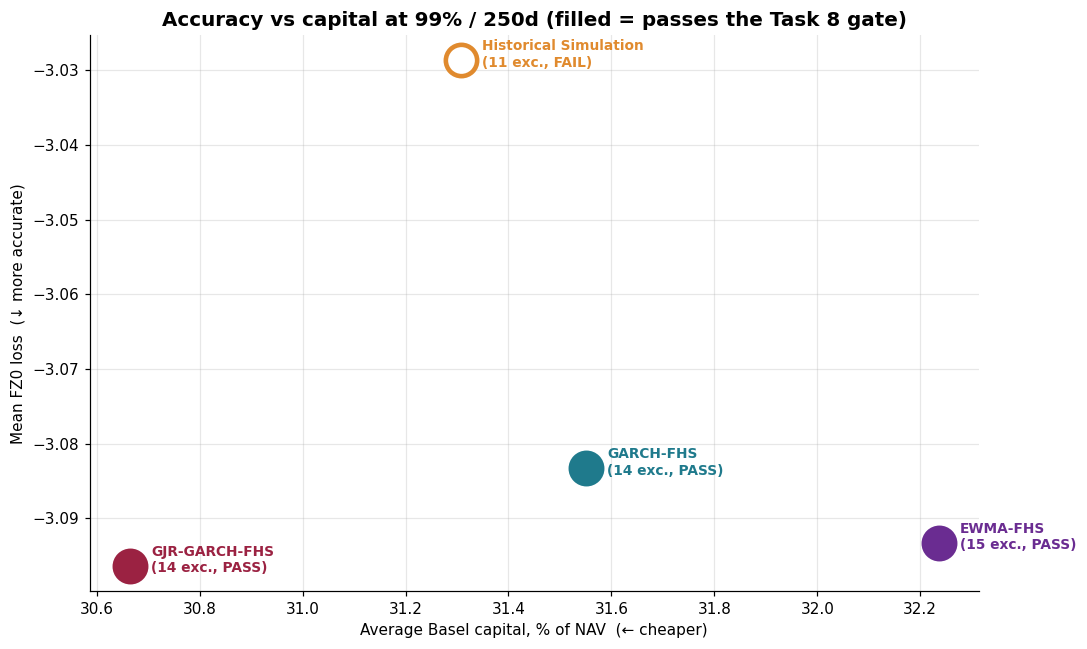

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
for m in MODELS:
    row = SC.loc[LABEL[m]]
    passed = row['Gate'] == 'PASS'
    ax.scatter(row['Avg capital % NAV'] * 100, row['FZ0 loss'], s=420, color=COLORS[m] if passed else 'white',
               edgecolor=COLORS[m], linewidth=3, zorder=5)
    ax.annotate(f"{LABEL[m]}\n({row['Exceptions']} exc., {row['Gate']})", (row['Avg capital % NAV'] * 100, row['FZ0 loss']),
                xytext=(14, -4), textcoords='offset points', fontsize=9, color=COLORS[m], fontweight='bold')
ax.set_xlabel('Average Basel capital, % of NAV  (← cheaper)'); ax.set_ylabel('Mean FZ0 loss  (↓ more accurate)')
ax.set_title('Accuracy vs capital at 99% / 250d (filled = passes the Task 8 gate)')
plt.tight_layout(); plt.show()

## 8. Decision

In [15]:
sc = SC.copy(); sc.index = list(MODELS)
pool = sc[sc['Gate'] == 'PASS']
gate_note = ''
if pool.empty:
    pool, gate_note = sc, 'No model passed every test at the headline, so the ranking uses all models; this is flagged for the committee. '
ranked = pool.sort_values('FZ0 loss')
leader = ranked.index[0]
CELLS_PASSED = RES.groupby('Model')['Verdict'].apply(lambda x: int((x == 'PASS').sum()))
tied = [leader] + [m for m in ranked.index[1:] if DMp.loc[leader, m] > 0.05]
key = lambda m: (-CELLS_PASSED[m], sc.loc[m, 'Avg capital % NAV'], COMPLEXITY[m])
choice = sorted(tied, key=key)[0]
if len(tied) == 1:
    reason = f'{LABEL[leader]} has the lowest FZ0 loss and is significantly more accurate than every other passing model.'
else:
    dmtxt = ', '.join(f'{LABEL[m]} (DM p = {DMp.loc[leader, m]:.2f})' for m in tied[1:])
    reason = (f'{LABEL[leader]} has the lowest FZ0 loss, but it is not significantly more accurate than {dmtxt}. '
              f'Among these statistically tied models, {LABEL[choice]} passes the backtest battery in the most cells '
              f'({CELLS_PASSED[choice]}/9), then has the lowest capital ({sc.loc[choice, "Avg capital % NAV"]:.1%} of NAV).')
    if choice != leader:
        reason += f' So the tie-break picks {LABEL[choice]} over the raw FZ0 leader.'
    else:
        reason += f' So the tie-break confirms {LABEL[choice]}.'
challenger = sorted([m for m in ranked.index if m != choice], key=lambda m: sc.loc[m, 'FZ0 loss'])[0] if len(ranked) > 1 else 'HS'

if os.path.exists(SUMMARY_FILE):
    s_ = pd.read_csv(SUMMARY_FILE).query('Model == @choice and Window == @HEADLINE_W and Confidence == @HEADLINE_CL').iloc[0]
    nd_var, nd_es = s_['Next-day VaR $'], s_['Next-day ES $']
else:
    nd_var = nd_es = np.nan
REC = {'recommended_model': choice, 'label': LABEL[choice], 'challenger': challenger, 'window': HEADLINE_W, 'confidence': HEADLINE_CL,
       'rationale': gate_note + reason, 'next_day_VaR_usd': float(nd_var), 'next_day_ES_usd': float(nd_es), 'nav_usd': NAV,
       'evaluation_start': str(d[0].date()), 'evaluation_end': str(d[-1].date()), 'author': AUTHOR,
       'generated_at': datetime.now().isoformat(timespec='seconds')}
with open('Model_Recommendation.json', 'w') as f:
    json.dump(REC, f, indent=2)
SC.to_csv('Model_Comparison.csv'); ROB.to_csv('Model_Comparison_AllCells.csv', index=False); dm_long.to_csv('DM_Tests.csv', index=False)
print(json.dumps(REC, indent=2))

{
  "recommended_model": "GJR",
  "label": "GJR-GARCH-FHS",
  "challenger": "EWMA",
  "window": 250,
  "confidence": 0.99,
  "rationale": "GJR-GARCH-FHS has the lowest FZ0 loss, but it is not significantly more accurate than EWMA-FHS (DM p = 0.95), GARCH-FHS (DM p = 0.72). Among these statistically tied models, GJR-GARCH-FHS passes the backtest battery in the most cells (7/9), then has the lowest capital (30.7% of NAV). So the tie-break confirms GJR-GARCH-FHS.",
  "next_day_VaR_usd": 210394.789476221,
  "next_day_ES_usd": 247131.34810431587,
  "nav_usd": 4520227.851424685,
  "evaluation_start": "2022-07-21",
  "evaluation_end": "2026-07-24",
  "author": "Arham Shah",
  "generated_at": "2026-10-11T02:04:50"
}


## 9. Executive summary

In [16]:
r_ = SC.loc[LABEL[choice]]; h_ = SC.loc[LABEL['HS']]
display(Markdown(f"""
### Recommendation: **{LABEL[choice]}** (99% / {HEADLINE_W}-day), challenger **{LABEL[challenger]}**

**Why.** {REC['rationale']}

| | {LABEL[choice]} | Historical Simulation |
|---|---|---|
| Exceptions ({r_['Expected']:.1f} expected) | {r_['Exceptions']} | {h_['Exceptions']} |
| Kupiec / CC / ES-test p | {r_['Kupiec p']:.2f} / {r_['CC p']:.2f} / {r_['ES test p']:.2f} | {h_['Kupiec p']:.2f} / {h_['CC p']:.2f} / {h_['ES test p']:.2f} |
| Basel zone today | {r_['Basel zone']} | {h_['Basel zone']} |
| Average capital (% NAV) | {r_['Avg capital % NAV']:.1%} | {h_['Avg capital % NAV']:.1%} |
| FZ0 loss (lower = better) | {r_['FZ0 loss']:.4f} | {h_['FZ0 loss']:.4f} |

**Next-day risk on NAV {money(NAV)}:** VaR **{money(nd_var)}**, ES **{money(nd_es)}**.

**Robustness.** Cells passing the Task 8 battery (of 9): {', '.join(f"{LABEL[m]} {CELLS_PASSED[m]}" for m in MODELS)}. The lowest FZ0 loss was won by:
{', '.join(f"{LABEL.get(k, k)} {v}" for k, v in wins['Best FZ0 (all)'].items() if v > 0 and k in LABEL)}.

**Honest caveats.** (1) Six years of mostly bull-market data, so rankings may differ in a prolonged crisis. (2) The DM tests show that some accuracy gaps
are **not** statistically significant, which is why the pre-set tie-break (robustness, then capital, then simplicity) decides. (3) VaR models describe *normal* tail risk only. **Task 10** stress-tests
the chosen model against historical and hypothetical scenarios that lie outside the backtest sample.
"""))


### Recommendation: **GJR-GARCH-FHS** (99% / 250-day), challenger **EWMA-FHS**

**Why.** GJR-GARCH-FHS has the lowest FZ0 loss, but it is not significantly more accurate than EWMA-FHS (DM p = 0.95), GARCH-FHS (DM p = 0.72). Among these statistically tied models, GJR-GARCH-FHS passes the backtest battery in the most cells (7/9), then has the lowest capital (30.7% of NAV). So the tie-break confirms GJR-GARCH-FHS.

| | GJR-GARCH-FHS | Historical Simulation |
|---|---|---|
| Exceptions (10.1 expected) | 14 | 11 |
| Kupiec / CC / ES-test p | 0.24 / 0.41 / 0.16 | 0.77 / 0.26 / 0.01 |
| Basel zone today | GREEN | GREEN |
| Average capital (% NAV) | 30.7% | 31.3% |
| FZ0 loss (lower = better) | -3.0964 | -3.0287 |

**Next-day risk on NAV $4,520,228:** VaR **$210,395**, ES **$247,131**.

**Robustness.** Cells passing the Task 8 battery (of 9): Historical Simulation 3, EWMA-FHS 6, GARCH-FHS 5, GJR-GARCH-FHS 7. The lowest FZ0 loss was won by:
EWMA-FHS 1, GJR-GARCH-FHS 7, Historical Simulation 1.

**Honest caveats.** (1) Six years of mostly bull-market data, so rankings may differ in a prolonged crisis. (2) The DM tests show that some accuracy gaps
are **not** statistically significant, which is why the pre-set tie-break (robustness, then capital, then simplicity) decides. (3) VaR models describe *normal* tail risk only. **Task 10** stress-tests
the chosen model against historical and hypothetical scenarios that lie outside the backtest sample.


---
*Task 9 complete. The production model and its next-day VaR/ES are saved in `Model_Recommendation.json` for Task 10.*

*Prepared by Arham Shah.*